In [1]:
%pip install pandas matplotlib seaborn

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/10.9 MB 9.3 MB/s eta 0:00:01
   -------- ------------------------------- 2.4/10.9 MB 5.8 MB/s eta 0:00:02
   ---------------- ----------------------- 4.5/10.9 MB 7.3 MB/s eta 0:00:01
   ---------------------- ----------------- 6.0/10.9 MB 7.5 MB/s eta 0:00:01
   -------------------------- ------------- 7.3/10.9 MB 7.3 MB/s eta 0:00:01
   ---------------------------------- ----- 9.4/10.9 MB 7.7 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 7.5 MB/s  0:00:01
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.5 MB 9.1 MB/s eta 0:00:01
   -------------- ------------------------- 3.4/9.5 MB 9.4 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.5 MB 8.7 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.5 MB 8.1 MB/s eta 0:00:01
   -----------------

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd
import numpy as np
df = pd.read_csv(r"C:\Users\Raj Naugariya\Desktop\hcl projrct\monthly_expenses_250.csv")
df.head()

,Name,Age,Job,Monthly Expense
0,Advaith Verma,28,Graphic Designer,"₹28,400"
1,Pranav Rathore,25,UX Designer,"₹55,600"
2,Arjun Verma,33,Product Manager,"₹75,500"
3,Preeti Verma,29,UX Designer,"₹63,600"
4,Aditi Pandey,56,Doctor,"₹1,27,500"


In [ ]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Load your dataset
csv_name = "monthly_expenses_250.csv"
csv_candidates = [
    Path.cwd() / csv_name,
    Path.cwd().parent / csv_name,
    Path.home() / "Downloads" / "HCLPROJECT1" / csv_name,
    Path.home() / "Downloads" / csv_name,
    Path.home() / "Desktop" / "hcl projrct" / csv_name,
]

csv_path = next((path for path in csv_candidates if path.is_file()), None)

if csv_path is None:
    raise FileNotFoundError(
        f"Could not find '{csv_name}'. Place it in the notebook folder or update csv_path."
    )

df = pd.read_csv(csv_path)
print(f"Loaded dataset from: {csv_path}")
df.columns = df.columns.str.strip()

# 2. Strip '₹', commas, or spaces and convert 'Monthly Expense' into pure numbers
df['Monthly Expense'] = (df['Monthly Expense']
    .astype(str)
    .str.replace(r'[^\d.]', '', regex=True)
)
df['Monthly Expense'] = pd.to_numeric(df['Monthly Expense'], errors='coerce')

# 3. Create the horizontal bar chart
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 7), facecolor='white')

avg_expense = df.groupby('Job')['Monthly Expense'].mean().sort_values(ascending=False)

sns.barplot(
    x=avg_expense.values, 
    y=avg_expense.index, 
    hue=avg_expense.index, 
    palette='viridis', 
    legend=False,
    ax=ax
)

ax.set_title('Average Monthly Expense by Job Role', fontsize=15, fontweight='bold')
ax.set_xlabel('Average Monthly Expense (INR)', fontsize=12)
ax.set_ylabel('Job Role', fontsize=12)

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Raj Naugariya\\Desktop\\hcl projrct\\monthly_expenses_250.csv'

Missing values per column:
Name               0
Age                0
Job                0
Monthly Expense    0
dtype: int64


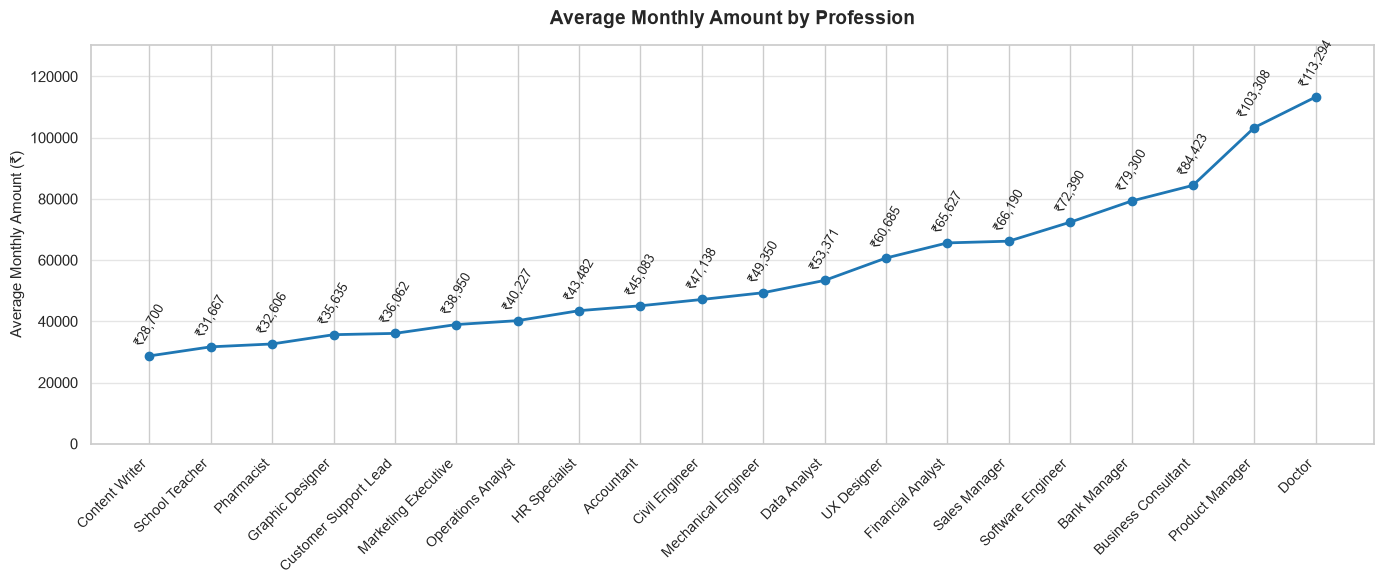

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset (update filename if needed)
df = pd.read_csv(r"C:\Users\Raj Naugariya\Desktop\hcl projrct\monthly_expenses_250.csv")

# 2. Clean 'Monthly Expense' if it contains '₹' or commas
df["Monthly Expense"] = (
    df["Monthly Expense"]
    .astype(str)
    .str.replace(r"[₹,]", "", regex=True)
    .str.strip()
    .astype(float)
)

# 3. Print missing values per column (as shown above the chart)
print("Missing values per column:")
print(df.isnull().sum())

# 4. Calculate average monthly amount by Job, sorted lowest to highest
job_avg = df.groupby("Job")["Monthly Expense"].mean().sort_values(ascending=True)

# 5. Create the plot
plt.figure(figsize=(14, 6))
plt.plot(job_avg.index, job_avg.values, marker="o", linewidth=2, markersize=6, color="#1f77b4")

# Title and Axis Labels
plt.title("Average Monthly Amount by Profession", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Average Monthly Amount (₹)", fontsize=11)
plt.ylim(0, job_avg.max() * 1.15)  # Give extra headroom at the top for labels

# Rotate x-axis labels 45 degrees
plt.xticks(rotation=45, ha="right", fontsize=10)

# Add horizontal gridlines
plt.grid(axis="y", linestyle="-", alpha=0.5)

# Add rotated ₹ value labels above each point
for i, val in enumerate(job_avg.values):
    plt.text(
        i,
        val + (job_avg.max() * 0.02),
        f"₹{val:,.0f}",
        rotation=60,
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

--- DATASET INFO ---
Total Records: 250
Missing Values:
Name               0
Age                0
Job                0
Monthly Expense    0
dtype: int64

--- SUMMARY STATISTICS ---
          Age  Monthly Expense
count  250.00           250.00
mean    37.06         57986.40
std      8.85         27242.67
min     22.00         19600.00
25%     30.00         36925.00
50%     36.00         50100.00
75%     43.00         73775.00
max     59.00        153000.00 

Correlation (Age vs. Monthly Expense): 0.46

--- TOP 5 HIGHEST SPENDING PROFESSIONS ---
                     Headcount  Avg_Expense  Median_Expense
Job                                                        
Doctor                      17    113294.12        109000.0
Product Manager             12    103308.33        104200.0
Business Consultant         13     84423.08         85100.0
Bank Manager                17     79300.00         83400.0
Software Engineer           10     72390.00         73350.0 

--- TOP 5 LOWEST SPENDING PR

C:\Users\Raj Naugariya\AppData\Local\Temp\ipykernel_13576\235535423.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


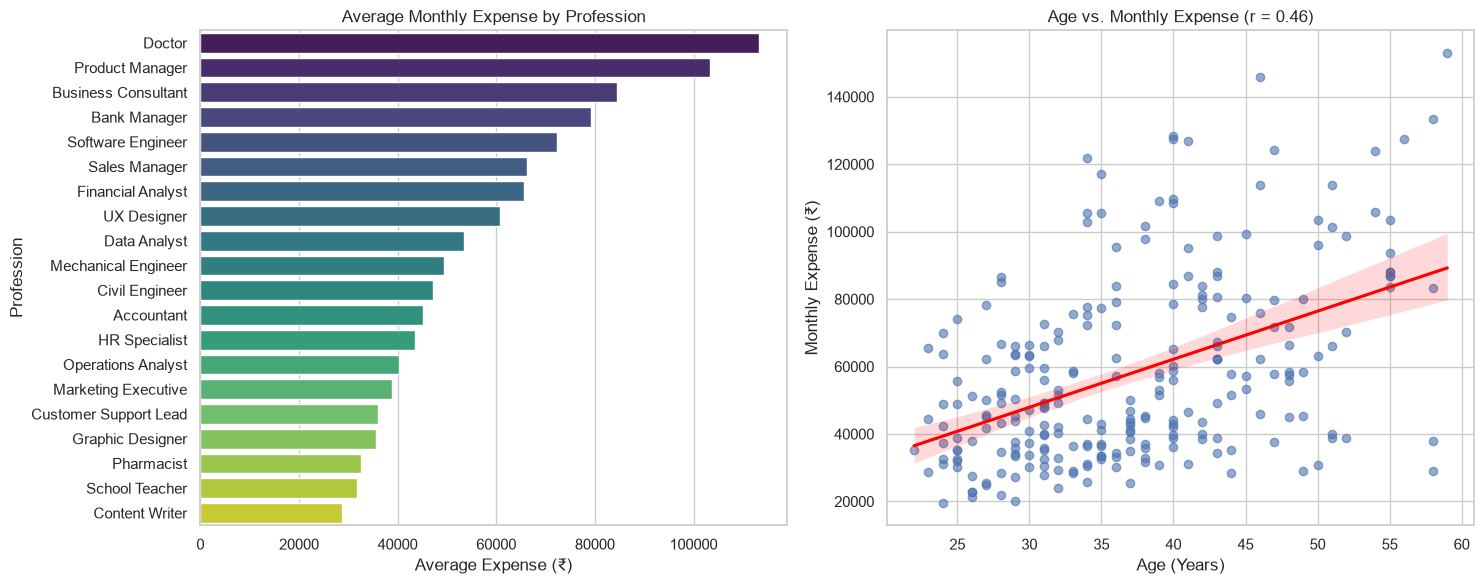

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('monthly_expenses_250.csv')

# 2. Clean the 'Monthly Expense' column and convert to numeric
df['Monthly Expense'] = pd.to_numeric(
    df['Monthly Expense'].astype(str).str.replace(r'[^\d.]', '', regex=True),
    errors='coerce'
)

# 3. General Dataset Overview
print("--- DATASET INFO ---")
print(f"Total Records: {len(df)}")
print(f"Missing Values:\n{df.isnull().sum()}\n")

print("--- SUMMARY STATISTICS ---")
print(df[['Age', 'Monthly Expense']].describe().round(2), "\n")

# 4. Correlation between Age and Monthly Expense
correlation = df['Age'].corr(df['Monthly Expense'])
print(f"Correlation (Age vs. Monthly Expense): {correlation:.2f}\n")

# 5. Spending & Headcount by Profession
job_summary = df.groupby('Job').agg(
    Headcount=('Name', 'count'),
    Avg_Expense=('Monthly Expense', 'mean'),
    Median_Expense=('Monthly Expense', 'median')
).round(2).sort_values(by='Avg_Expense', ascending=False)

print("--- TOP 5 HIGHEST SPENDING PROFESSIONS ---")
print(job_summary.head(5), "\n")

print("--- TOP 5 LOWEST SPENDING PROFESSIONS ---")
print(job_summary.tail(5), "\n")

# 6. Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Average Monthly Expense by Profession
sns.barplot(
    x=job_summary['Avg_Expense'],
    y=job_summary.index,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Average Monthly Expense by Profession')
axes[0].set_xlabel('Average Expense (₹)')
axes[0].set_ylabel('Profession')

# Plot 2: Age vs. Monthly Expense Scatter Plot with Trendline
sns.regplot(
    data=df,
    x='Age',
    y='Monthly Expense',
    ax=axes[1],
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)
axes[1].set_title(f'Age vs. Monthly Expense (r = {correlation:.2f})')
axes[1].set_xlabel('Age (Years)')
axes[1].set_ylabel('Monthly Expense (₹)')

plt.tight_layout()
plt.show()